<a href="https://colab.research.google.com/github/rtkmilaa/Ratih-Kamila-Khairani_SKB-2024/blob/main/Ratih_Kamila_Khairani_055283881_Machine_Learning_Tugas_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas 1 — Data Preprocessing Dataset Mahasiswa

**Mata kuliah:** Machine Learning
**Tujuan:** Menyiapkan dataset mahasiswa melalui EDA, penanganan missing values, normalisasi tanggal, encoding data kategorikal, pembagian data, dan visualisasi.

**File input:** `dataset_tugas1_preprocessing.csv`

## Tahap 1 — Load Dataset


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Membaca dataset dari file CSV
df = pd.read_csv("dataset_tugas1_preprocessing.csv")

print("Dataset berhasil dibaca.")
print("Ukuran dataset (baris, kolom):", df.shape)
display(df.head())

Dataset berhasil dibaca.
Ukuran dataset (baris, kolom): (99, 8)


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,13-04-2020,NaN
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020/12/11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,2021/11/21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021/08/19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020/01/05,26.0


## Tahap 2 — Eksplorasi Awal (EDA)

EDA dilakukan untuk memahami struktur data sebelum dibersihkan. Pemeriksaan meliputi ukuran dataset, nama kolom, tipe data, nilai kosong, data duplikat, dan statistik deskriptif.

In [3]:
# Struktur dan tipe data
print("Informasi dataset:")
df.info()

print("\\nTipe data setiap kolom:")
display(df.dtypes.to_frame(name="Tipe Data"))

print("\\nStatistik deskriptif:")
display(df.describe(include="all").T)

print("\\nJumlah missing values per kolom:")
missing_awal = df.isnull().sum().to_frame(name="Jumlah Missing Values")
missing_awal["Persentase (%)"] = (missing_awal["Jumlah Missing Values"] / len(df) * 100).round(2)
display(missing_awal)

print("\\nJumlah baris duplikat:", df.duplicated().sum())

print("\\nJumlah nilai unik pada kolom kategorikal:")
for kolom in df.select_dtypes(include=["object"]).columns:
    print(f"{kolom}: {df[kolom].nunique(dropna=True)} nilai unik")


Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     object 
 1   Nama           99 non-null     object 
 2   Jenis_Kelamin  99 non-null     object 
 3   Prodi          99 non-null     object 
 4   Status         99 non-null     object 
 5   Nilai_Akhir    70 non-null     object 
 6   Tanggal_Ujian  99 non-null     object 
 7   Umur           90 non-null     float64
dtypes: float64(1), object(7)
memory usage: 6.3+ KB
\nTipe data setiap kolom:


,Tipe Data
ID,object
Nama,object
Jenis_Kelamin,object
Prodi,object
Status,object
Nilai_Akhir,object
Tanggal_Ujian,object
Umur,float64


\nStatistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,99,99,MH001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nama,99,10,Eka,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jenis_Kelamin,99,2,Laki-laki,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Prodi,99,4,Teknik Komputer,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,99,4,Cuti,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nilai_Akhir,70,5,C,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tanggal_Ujian,99,97,2020/03/31,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Umur,90.0,NaN,NaN,NaN,23.366667,3.763963,18.0,20.0,23.0,26.0,30.0


\nJumlah missing values per kolom:


,Jumlah Missing Values,Persentase (%)
ID,0,0.00
Nama,0,0.00
Jenis_Kelamin,0,0.00
Prodi,0,0.00
Status,0,0.00
Nilai_Akhir,29,29.29
Tanggal_Ujian,0,0.00
Umur,9,9.09


\nJumlah baris duplikat: 0
\nJumlah nilai unik pada kolom kategorikal:
ID: 99 nilai unik
Nama: 10 nilai unik
Jenis_Kelamin: 2 nilai unik
Prodi: 4 nilai unik
Status: 4 nilai unik
Nilai_Akhir: 5 nilai unik
Tanggal_Ujian: 97 nilai unik


## Tahap 3 — Menangani Missing Values


In [4]:
df_clean = df.copy()

# Simpan nilai imputasi agar transparan dan dapat dilaporkan
modus_nilai_akhir = df_clean["Nilai_Akhir"].mode(dropna=True)[0]
median_umur = df_clean["Umur"].median()

df_clean["Nilai_Akhir"] = df_clean["Nilai_Akhir"].fillna(modus_nilai_akhir)
df_clean["Umur"] = df_clean["Umur"].fillna(median_umur)

print("Modus untuk Nilai_Akhir:", modus_nilai_akhir)
print("Median untuk Umur:", median_umur)

print("\\nMissing values setelah imputasi:")
display(df_clean.isnull().sum().to_frame(name="Jumlah Missing Values"))

Modus untuk Nilai_Akhir: C
Median untuk Umur: 23.0
\nMissing values setelah imputasi:


,Jumlah Missing Values
ID,0
Nama,0
Jenis_Kelamin,0
Prodi,0
Status,0
Nilai_Akhir,0
Tanggal_Ujian,0
Umur,0


## Tahap 4 — Normalisasi Format Tanggal

konversi ke tipe datetime menggunakan `pandas.to_datetime`. Opsi `dayfirst=True` digunakan karena tanggal yang ditulis dengan pola seperti `13-04-2020` menunjukkan urutan hari-bulan-tahun. Hasil konversi diperiksa agar tanggal yang tidak valid dapat diketahui.

In [5]:
df_clean["Tanggal_Ujian"] = pd.to_datetime(
    df_clean["Tanggal_Ujian"],
    errors="coerce",
    dayfirst=True
)

print("Tipe data setelah konversi:", df_clean["Tanggal_Ujian"].dtype)
print("Jumlah tanggal yang gagal dikonversi:", df_clean["Tanggal_Ujian"].isna().sum())
display(df_clean[["Tanggal_Ujian"]].head(10))

Tipe data setelah konversi: datetime64[ns]
Jumlah tanggal yang gagal dikonversi: 89


,Tanggal_Ujian
0,2020-04-13
1,NaT
2,NaT
3,NaT
4,NaT
5,NaT
6,NaT
7,NaT
8,NaT
9,NaT


## Tahap 5 — Encoding Label

Label Encoding mengubah kategori menjadi kode bilangan bulat agar dapat diproses oleh algoritma machine learning. Sesuai instruksi, encoding diterapkan pada kolom `Nama`, `Jenis_Kelamin`, `Prodi`, `Status`, dan `Nilai_Akhir`.

In [6]:
kolom_kategorikal = [
    "Nama",
    "Jenis_Kelamin",
    "Prodi",
    "Status",
    "Nilai_Akhir"
]

df_encoded = df_clean.copy()
label_encoders = {}
pemetaan_label = {}

for kolom in kolom_kategorikal:
    encoder = LabelEncoder()
    df_encoded[kolom] = encoder.fit_transform(df_encoded[kolom].astype(str))
    label_encoders[kolom] = encoder
    pemetaan_label[kolom] = {
        kategori: int(kode)
        for kode, kategori in enumerate(encoder.classes_)
    }

for kolom, mapping in pemetaan_label.items():
    print(f"\\nPemetaan {kolom}:")
    print(mapping)

print("\\nDataset setelah Label Encoding:")
display(df_encoded.head())

\nPemetaan Nama:
{'Adi': 0, 'Budi': 1, 'Citra': 2, 'Dina': 3, 'Eka': 4, 'Farhan': 5, 'Gita': 6, 'Hana': 7, 'Iwan': 8, 'Joko': 9}
\nPemetaan Jenis_Kelamin:
{'Laki-laki': 0, 'Perempuan': 1}
\nPemetaan Prodi:
{'Data Science': 0, 'Informatika': 1, 'Sistem Informasi': 2, 'Teknik Komputer': 3}
\nPemetaan Status:
{'Aktif': 0, 'Cuti': 1, 'DO': 2, 'Lulus': 3}
\nPemetaan Nilai_Akhir:
{'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4}
\nDataset setelah Label Encoding:


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,8,0,3,0,2,2020-04-13,23.0
1,MH002,4,1,3,3,4,NaT,28.0
2,MH003,8,0,3,0,2,NaT,23.0
3,MH004,4,1,3,0,3,NaT,18.0
4,MH005,9,1,0,0,2,NaT,26.0


## Persiapan tanggal sebagai fitur numerik

Setelah dikonversi ke datetime, kolom tanggal belum berupa angka yang dapat langsung digunakan oleh banyak model. Untuk kebutuhan pembagian data contoh ini, tanggal diubah menjadi jumlah hari sejak tanggal ujian paling awal.
Jika terdapat tanggal yang gagal dikonversi, nilai tanggal numeriknya diisi dengan median agar fitur tidak menyisakan nilai kosong.

In [7]:
tanggal_awal = df_clean["Tanggal_Ujian"].min()

df_encoded["Hari_sejak_tanggal_awal"] = (
    df_clean["Tanggal_Ujian"] - tanggal_awal
).dt.days

# Isi nilai tanggal numerik yang mungkin kosong karena tanggal tidak valid
median_hari = df_encoded["Hari_sejak_tanggal_awal"].median()
df_encoded["Hari_sejak_tanggal_awal"] = (
    df_encoded["Hari_sejak_tanggal_awal"].fillna(median_hari)
)

display(df_encoded[["Tanggal_Ujian", "Hari_sejak_tanggal_awal"]].head())

,Tanggal_Ujian,Hari_sejak_tanggal_awal
0,2020-04-13,0.0
1,NaT,275.5
2,NaT,275.5
3,NaT,275.5
4,NaT,275.5


## Tahap 6 — Split Data (80% Data Latih dan 20% Data Uji)

`Status` dipilih sebagai variabel target (`y`), sedangkan kolom lainnya selain `ID` dan tanggal datetime asli digunakan sebagai fitur (`X`).
`random_state=42` digunakan agar hasil pembagian dapat direproduksi. `stratify=y` digunakan untuk membantu mempertahankan proporsi kelas target pada data latih dan data uji jika jumlah setiap kelas memungkinkan.

In [8]:
# Hapus ID dan tanggal datetime asli; gunakan fitur tanggal numerik
data_model = df_encoded.drop(columns=["ID", "Tanggal_Ujian"])

X = data_model.drop(columns=["Status"])
y = data_model["Status"]

# Gunakan stratifikasi jika setiap kelas memiliki setidaknya dua anggota
jumlah_kelas = y.value_counts()
gunakan_stratify = y if (len(jumlah_kelas) > 1 and jumlah_kelas.min() >= 2) else None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=gunakan_stratify
)

print("Total baris:", len(data_model))
print("Data latih:", len(X_train), f"({len(X_train)/len(data_model):.1%})")
print("Data uji:", len(X_test), f"({len(X_test)/len(data_model):.1%})")
print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test:", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test:", y_test.shape)

Total baris: 99
Data latih: 79 (79.8%)
Data uji: 20 (20.2%)
Ukuran X_train: (79, 6)
Ukuran X_test: (20, 6)
Ukuran y_train: (79,)
Ukuran y_test: (20,)


## Tahap 7 — Visualisasi

Dua visualisasi: histogram distribusi umur mahasiswa dan grafik batang jumlah mahasiswa berdasarkan program studi. Visualisasi menggunakan data setelah penanganan missing values

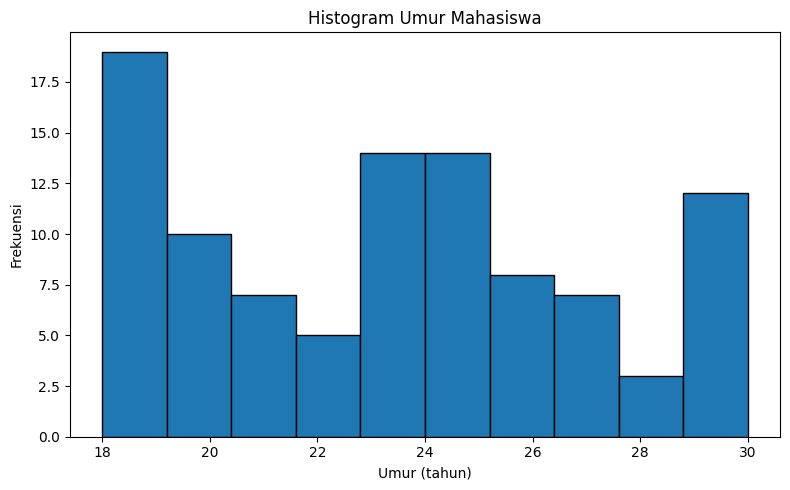

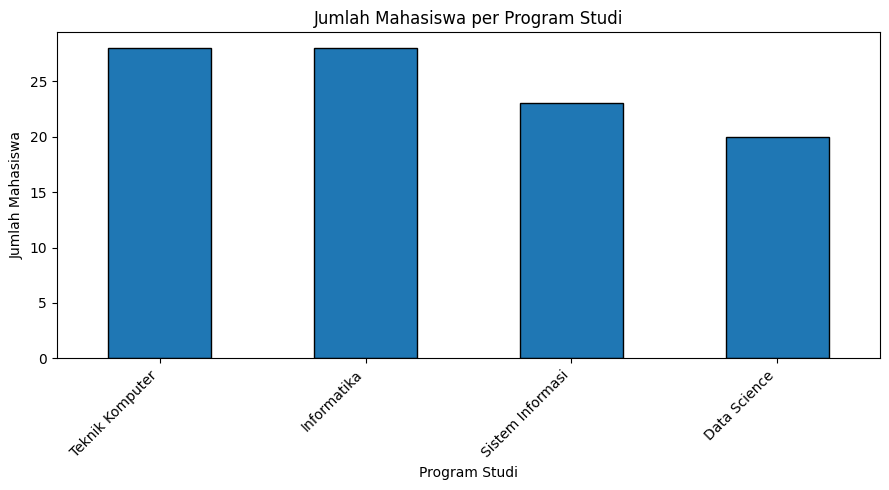

,Jumlah Mahasiswa
Prodi,
Teknik Komputer,28
Informatika,28
Sistem Informasi,23
Data Science,20


In [9]:
# Histogram kolom Umur
plt.figure(figsize=(8, 5))
plt.hist(df_clean["Umur"], bins=10, edgecolor="black")
plt.title("Histogram Umur Mahasiswa")
plt.xlabel("Umur (tahun)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

# Grafik batang jumlah mahasiswa per Prodi
jumlah_mahasiswa_prodi = df_clean["Prodi"].value_counts()

plt.figure(figsize=(9, 5))
jumlah_mahasiswa_prodi.plot(kind="bar", edgecolor="black")
plt.title("Jumlah Mahasiswa per Program Studi")
plt.xlabel("Program Studi")
plt.ylabel("Jumlah Mahasiswa")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(jumlah_mahasiswa_prodi.to_frame(name="Jumlah Mahasiswa"))

## Ringkasan Hasil dan Kesimpulan

Dataset mahasiswa dimuat dan dicek kembali melalui EDA. Nilai kosong pada `Nilai_Akhir` diimputasi menggunakan modus dan pada `Umur` menggunakan median. Format `Tanggal_Ujian` dikonversi ke datetime, kolom kategorikal yang diminta diubah menjadi kode numerik menggunakan Label Encoding, dan data dibagi menjadi data latih serta data uji dengan proporsi 80:20. Histogram umur dan grafik batang jumlah mahasiswa per program studi digunakan untuk melihat distribusi data.

## Materi Pengayaan yang Digunakan

1. [EDA Sesi 3 — Integrasi Data](https://github.com/ayyash-ayyub/RAT_dan_OER_FST_SD_UT_2025/blob/main/EDA_Sesi_3_Machine_Learning_Integrasi_data.ipynb)
2. [Latihan Penanganan Missing Data (CSV)](https://github.com/ayyash-ayyub/RAT_dan_OER_FST_SD_UT_2025/blob/main/latihan_penanganan_missing_data.csv)
3. [EDA Sesi 3 — Missing Values Case](https://github.com/ayyash-ayyub/RAT_dan_OER_FST_SD_UT_2025/blob/main/EDA_Sesi_3_Machine_Learning_Missing_Values_Case.ipynb)
4. [EDA Sesi 3 — Kategori Data](https://github.com/ayyash-ayyub/bahan_ajar_oer/blob/main/EDA_Sesi_3_Machine_Learning_Kategori_data.ipynb)
5. [Latihan Time Series (CSV)](https://github.com/ayyash-ayyub/RAT_dan_OER_FST_SD_UT_2025/blob/main/latihan_timeseries.csv)
6. [EDA Sesi 3 — Time Series](https://github.com/ayyash-ayyub/RAT_dan_OER_FST_SD_UT_2025/blob/main/EDA_Sesi_3_Machine_Learning_timeseries.ipynb)
7. [EDA Sesi 3 — Split Dataset](https://github.com/ayyash-ayyub/RAT_dan_OER_FST_SD_UT_2025/blob/main/EDA_Sesi_3_Machine_Learning_Split_Dataset.ipynb)
